# CNN Segmentation

In [140]:
# Imports


import numpy as np
import matplotlib.pyplot as plt
import h5py
from pathlib import Path
from collections import defaultdict
from sklearn.model_selection import train_test_split
from scipy.ndimage import gaussian_filter


import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


print("Imports successful")

Imports successful


## Loading the Data

In [141]:
DATA_DIR = Path("data/raw/BraTS2020_training_data")
h5_files = sorted(DATA_DIR.glob("*.h5"))

print("Total .h5 files:", len(h5_files))
print("Example file:", h5_files[0].name)

Total .h5 files: 57195
Example file: volume_100_slice_0.h5


## Grouping the Slice Files by Volume

In [ ]:
# grouping slices by volume to avoid data leakage later on 
volume_to_files = defaultdict(list)

for f in h5_files:
    parts = f.stem.split("_")
    volume_id = f"{parts[0]}_{parts[1]}"
    volume_to_files[volume_id].append(f)

for volume_id in volume_to_files:
    volume_to_files[volume_id] = sorted(
        volume_to_files[volume_id],
        key=lambda x: int(x.stem.split("_")[-1])
    )

print("Total volumes:", len(volume_to_files))
print("Example volumes:", list(volume_to_files.keys())[:5])

Total volumes: 369
Example volumes: ['volume_100', 'volume_101', 'volume_102', 'volume_103', 'volume_104']


## Choosing our Volume Subset (30 for now)

In [ ]:
# Tried running 30 volumes at first, output was > 30 minutes before cancelled.
# Trying 5 to see if any difference 

selected_volumes = list(volume_to_files.keys())[:5]

print("Selected volumes:", selected_volumes)

Selected volumes: ['volume_100', 'volume_101', 'volume_102', 'volume_103', 'volume_104']


# Training, Validation, Testing Splits 

In [ ]:
# Splitting into 70/15/15 training, validation, and testing sets 

train_vols, temp_vols = train_test_split(selected_volumes, test_size=0.3, random_state=42)
val_vols, test_vols = train_test_split(temp_vols, test_size=0.5, random_state=42)

print("Train volumes:", train_vols)
print("Validation volumes:", val_vols)
print("Test volumes:", test_vols)

Train volumes: ['volume_102', 'volume_100', 'volume_103']
Validation volumes: ['volume_101']
Test volumes: ['volume_104']


In [ ]:
# inspecting number of each

def collect_files(volume_list, volume_to_files_dict):
    files = []
    for vol in volume_list:
        files.extend(volume_to_files_dict[vol])
    return files

train_files = collect_files(train_vols, volume_to_files)
val_files = collect_files(val_vols, volume_to_files)
test_files = collect_files(test_vols, volume_to_files)

print("Train files:", len(train_files))
print("Validation files:", len(val_files))
print("Test files:", len(test_files))

Train files: 465
Validation files: 155
Test files: 155


# Loading MRI Slice and the Mask 

In [146]:
# Loading one .h5 file and return image and mask
def load_h5_sample(file_path):
    with h5py.File(file_path, "r") as f:
        image = f["image"][:]   
        mask = f["mask"][:]     
    return image, mask

# Convert Mask to Binary Whole-Tumor Mask 

In [147]:
# Converting the 3-channel mask into a single binary tumor mask
def make_binary_mask(mask):
    # If any of the 3 channels has tumor, it sets it to 1
    return (mask.sum(axis=-1) > 0).astype("uint8")

# Preprocessing: Intensity Normalization (Through Z-Score)

In [148]:
# Normalizing each MRI channel (mean=0, std=1)
def normalize(image):
    norm = np.zeros_like(image)

    for i in range(image.shape[-1]):  # This loops over the 4 channels
        channel = image[:, :, i]
        mean = channel.mean()
        std = channel.std()

        norm[:, :, i] = (channel - mean) / (std + 1e-8)

    return norm

# Preprocessing: Gaussian 

In [149]:
# Applying Gaussian blur to each channel to reduce noise
def apply_gaussian(image, sigma=1):
    smoothed = np.zeros_like(image)

    for i in range(image.shape[-1]):  # looping over 4 channels
        smoothed[:, :, i] = gaussian_filter(image[:, :, i], sigma=sigma)

    return smoothed

# Preprocessing Selection for CNN

In [150]:
# Baseline (no preprocessing)
def preprocess_baseline(image):
    return image

# Intensity Normalization Only
def preprocess_norm(image):
    return normalize(image)

# Gaussian Smoothing Only

def preprocess_gauss(image):
    return apply_gaussian(image, sigma=1)

# Choosing Which Preprocessing Method Here:

In [ ]:
# Change between preprocess_norm, preprocess_baseline, and preprocess_gauss to compare the preprocessing methods here**
# Comment out whichever you aren't using at the time, and change the -  
# preprocess_function to the specific technique you want to use. 

preprocess_function = preprocess_baseline
# Preprocess_Name = "Normalized"
Preprocess_Name = "No Preprocessing Applied"
# Preprocess_Name = "Gaussian"

print("Current preprocessing:", Preprocess_Name)

Current preprocessing: No Preprocessing Applied


# Defining Dataset 

In [152]:
class BrainSliceDataset(Dataset):
    def __init__(self, file_list, preprocess_function=None, tumor_only=False):
        """
        file_list: list of .h5 file paths
        preprocess_function: preprocessing function (baseline, normalization, or Gaussian)
        tumor_only: if True, keep only slices that contain tumor
        """
        self.file_list = file_list
        self.preprocess_function = preprocess_function
        self.tumor_only = tumor_only

        # Filtering only the tumor containing slices here
        if self.tumor_only:
            filtered_files = []
            for file_path in self.file_list:
                _, mask = load_h5_sample(file_path)
                binary_mask = make_binary_mask(mask)

                if binary_mask.sum() > 0:
                    filtered_files.append(file_path)

            self.file_list = filtered_files

    def __len__(self):
        # Number of samples in dataset
        return len(self.file_list)

    def __getitem__(self, idx):
        file_path = self.file_list[idx]

        # Loading the image and mask
        image, mask = load_h5_sample(file_path)
        binary_mask = make_binary_mask(mask)

        # Apply preprocessing
        if self.preprocess_function is not None:
            image = self.preprocess_function(image)

        # Need to transpose the image for PyTorch
        image = np.transpose(image, (2, 0, 1)).astype(np.float32)

        # Converting mask for PyTorch also
        binary_mask = np.expand_dims(binary_mask, axis=0).astype(np.float32)

        return torch.tensor(image), torch.tensor(binary_mask)

# Updating the Datasets

In [ ]:
# Updating the dataset objects 
# Had to keep all training slices, but tried to restrict validation and test to only tumor-containing slices 
# Otherwise outputs aren't very meaningful 
# Visual examples can get dominated by empty masks if not 

train_dataset = BrainSliceDataset(
    train_files,
    preprocess_function=preprocess_function,
    tumor_only=False
)
val_dataset = BrainSliceDataset(
    val_files,
    preprocess_function=preprocess_function,
    tumor_only=True
)
test_dataset = BrainSliceDataset(
    test_files,
    preprocess_function=preprocess_function,
    tumor_only=True
)

## Creating the DataLoaders

In [154]:
# Metrics after updating the datasets above 

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Train samples: 465
Validation samples: 57
Test samples: 80


# Making the PyTorch Data Loaders 

In [155]:
# PyTorch DataLoaders 
# Recreated loaders so validation/test use the tumor-only datasets 
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False)

print("DataLoaders created successfully")

DataLoaders created successfully


# Checking example to make sure works 

In [156]:
# Checking that one sample has the expected shape
# image tensor shape should be (4, 240, 240) / mask tensor shape should be (1, 240, 240)
sample_image, sample_mask = train_dataset[0]

print("Image tensor shape:", sample_image.shape)   
print("Mask tensor shape:", sample_mask.shape)     
print("Image dtype:", sample_image.dtype)
print("Mask dtype:", sample_mask.dtype)

Image tensor shape: torch.Size([4, 240, 240])
Mask tensor shape: torch.Size([1, 240, 240])
Image dtype: torch.float32
Mask dtype: torch.float32


# Visualizing Sample 

Tumor sample index: 79
Tumor pixels in mask: 34.0


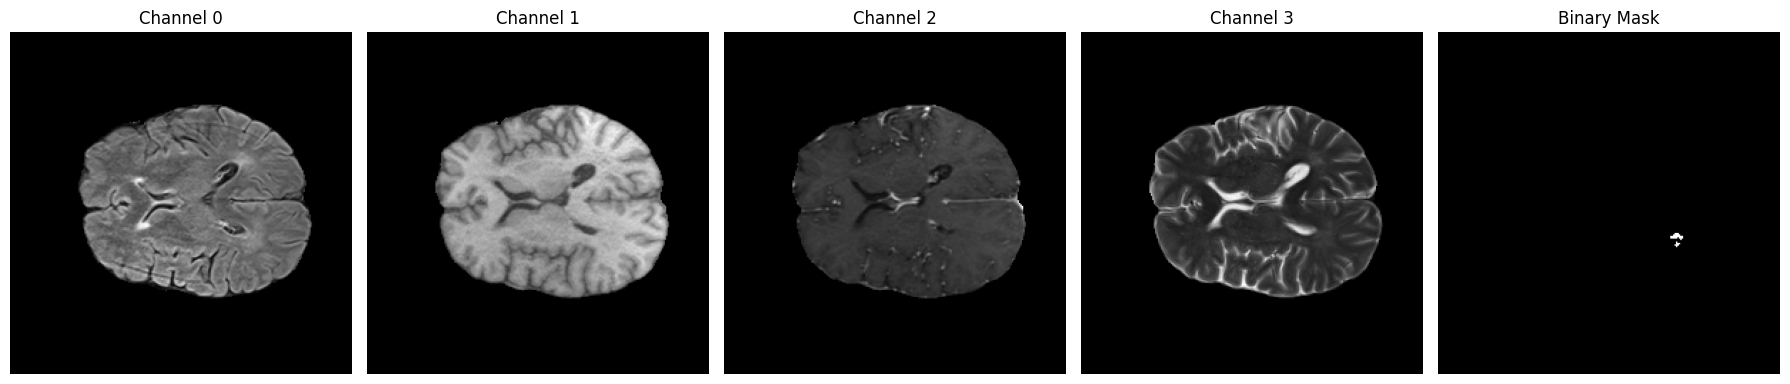

In [157]:
# Find the first training sample that actually contains tumor
tumor_idx = None

for i in range(len(train_dataset)):
    img, msk = train_dataset[i]
    if msk.sum().item() > 0:
        tumor_idx = i
        break

print("Tumor sample index:", tumor_idx)

sample_image, sample_mask = train_dataset[tumor_idx]

print("Tumor pixels in mask:", sample_mask.sum().item())


# Show all 4 MRI channels plus the binary mask
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for c in range(4):
    channel = sample_image[c].numpy()
    axes[c].imshow(channel, cmap="gray", vmin=channel.min(), vmax=channel.max())
    axes[c].set_title(f"Channel {c}")
    axes[c].axis("off")

axes[4].imshow(sample_mask[0].numpy(), cmap="gray", vmin=0, vmax=1)
axes[4].set_title("Binary Mask")
axes[4].axis("off")

plt.tight_layout()
plt.show()


## CNN Creation - Simple UNet

# Defining UNet Model

In [ ]:
# Loading a U-Net model from PyTorch Hub
# Using 4 input channels for the 4 MRI modalities
# Using 1 output channel for binary whole-tumor segmentation
# https://pytorch.org/hub/mateuszbuda_brain-segmentation-pytorch_unet/

import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = torch.hub.load(
    "mateuszbuda/brain-segmentation-pytorch",
    "unet",
    in_channels=4,
    out_channels=1,
    init_features=32,
    pretrained=False,
    trust_repo=True
).to(device)

print("U-Net model loaded successfully")

Using device: cpu
U-Net model loaded successfully


Using cache found in C:\Users\clrob/.cache\torch\hub\mateuszbuda_brain-segmentation-pytorch_master


# Loss Function and Optimizer

In [ ]:
# Adam is a good starting optimizer i believe

# criterion = nn.BCEWithLogitsLoss()
# Loss above unsuccessful


def dice_loss(pred, target):
    pred = torch.sigmoid(pred)
    smooth = 1e-8

    intersection = (pred * target).sum()
    union = pred.sum() + target.sum()

    return 1 - ((2.0 * intersection + smooth) / (union + smooth))


def combined_loss(pred, target):
    bce = nn.BCEWithLogitsLoss()(pred, target)
    d_loss = dice_loss(pred, target)
    return bce + d_loss

criterion = combined_loss
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print("Loss and optimizer successful")

# Dice loss serves to help focus on overlap with the smaller tumor regions?
# BCE loss + Dice loss included 
# Criterion is combined loss


Loss and optimizer successful


## Check Model Input and Output Shapes

In [160]:
# Confirming output shapes
# Believe it should be (4,4,240,240) for input, (4,1,240,240) for mask
# and (4,1,240,240) for output

images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

outputs = model(images)

print("Input shape:", images.shape)    
print("Mask shape:", masks.shape)      
print("Output shape:", outputs.shape)  

Input shape: torch.Size([4, 4, 240, 240])
Mask shape: torch.Size([4, 1, 240, 240])
Output shape: torch.Size([4, 1, 240, 240])


## Define Training and Validation Functions

In [161]:
# One training epoch
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, masks)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    return running_loss / len(loader)

In [162]:
# One validation epoch
def validate_one_epoch(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)
            loss = criterion(outputs, masks)

            running_loss += loss.item()

    return running_loss / len(loader)

## Training the UNet 

In [163]:
# Starting small with 2 epochs to see if its working 
# 2 epochs with 30 volumes appeared to take way too long
# Dropped to 5 volumes with 2 epochs
# Epoch 1/2 took about 3 1/2 minutes, Epoch 2/2 about 3 mins 
# num_epochs = 2
# Increased to 5 epochs for more learning ability for the CNN 
# Took about ~14 minutes to run for preprocess_norm
# Took 14:45 for preprocess_baseline
# Took 14:02 for preprocess_gauss


num_epochs = 5

train_losses = []
val_losses = []

for epoch in range(num_epochs):
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss = validate_one_epoch(model, val_loader, criterion, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"Epoch {epoch + 1}/{num_epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

Epoch 1/5 | Train Loss: 1.8278 | Val Loss: 1.7325
Epoch 2/5 | Train Loss: 1.7199 | Val Loss: 1.6567
Epoch 3/5 | Train Loss: 1.6871 | Val Loss: 1.6428
Epoch 4/5 | Train Loss: 1.6782 | Val Loss: 1.6393
Epoch 5/5 | Train Loss: 1.6736 | Val Loss: 1.6361


## Plot Training and Validation Loss

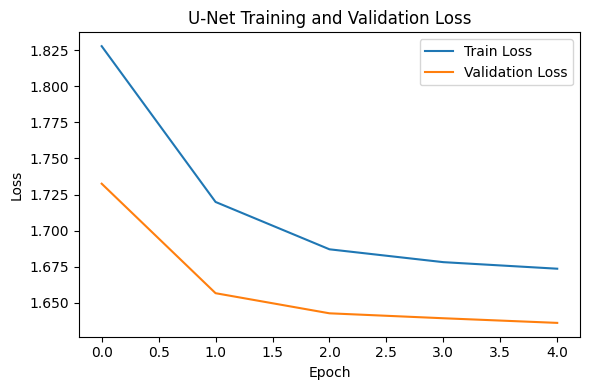

In [164]:
# assessing for convergence behavior and learning efficiency through the different epochs 

plt.figure(figsize=(6, 4))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("U-Net Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

## Define Evaluation Metrics

In [ ]:
# Computing the Dice, Sensitivity, and PPV for binary segmentation
def compute_metrics(pred, gt):
    pred = pred.astype(np.uint8)
    gt = gt.astype(np.uint8)

    TP = np.sum((pred == 1) & (gt == 1))
    FP = np.sum((pred == 1) & (gt == 0))
    FN = np.sum((pred == 0) & (gt == 1))

    dice = (2 * TP) / (2 * TP + FP + FN + 1e-8)
    sensitivity = TP / (TP + FN + 1e-8)
    ppv = TP / (TP + FP + 1e-8)

    return dice, sensitivity, ppv

## Evaluate the U-Net on Test Data

In [ ]:
model.eval()

all_dice = []
all_sensitivity = []
all_ppv = []

saved_examples = []

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)
        probs = torch.sigmoid(outputs)
        
        
        # preds = (probs > 0.5).float()
        # Using a higher threshold here 
        # Previous thresholds seemed to be causing over segmentation  
        # 0.6 threshold works much better
        preds = (probs > 0.6).float()


        for i in range(images.shape[0]):
            pred_np = preds[i, 0].cpu().numpy()
            mask_np = masks[i, 0].cpu().numpy()
            img_np = images[i].cpu().numpy()

            dice, sensitivity, ppv = compute_metrics(pred_np, mask_np)

            all_dice.append(dice)
            all_sensitivity.append(sensitivity)
            all_ppv.append(ppv)

            # Saving here only the tumor-containing examples for visualization 
            # if len(saved_examples) < 3:
                # saved_examples.append((img_np, mask_np, pred_np))
            if mask_np.sum() > 50 and len(saved_examples) < 3:
                saved_examples.append((img_np, mask_np, pred_np, dice, sensitivity, ppv))


# print("U-Net Results")
# print(f"Mean Dice: {np.mean(all_dice):.4f}")
# print(f"Mean Sensitivity: {np.mean(all_sensitivity):.4f}")
# print(f"Mean PPV: {np.mean(all_ppv):.4f}")

# Changed here to include mean +- STD 
print("U-Net Results")
print(f"Number of evaluated test slices: {len(all_dice)}")
print(f"Dice: {np.mean(all_dice):.4f} ± {np.std(all_dice):.4f}")
print(f"Sensitivity: {np.mean(all_sensitivity):.4f} ± {np.std(all_sensitivity):.4f}")
print(f"PPV: {np.mean(all_ppv):.4f} ± {np.std(all_ppv):.4f}")

U-Net Results
Number of evaluated test slices: 80
Dice: 0.8330 ± 0.1549
Sensitivity: 0.9356 ± 0.1260
PPV: 0.7696 ± 0.1719


## Visualize U-Net Predictions

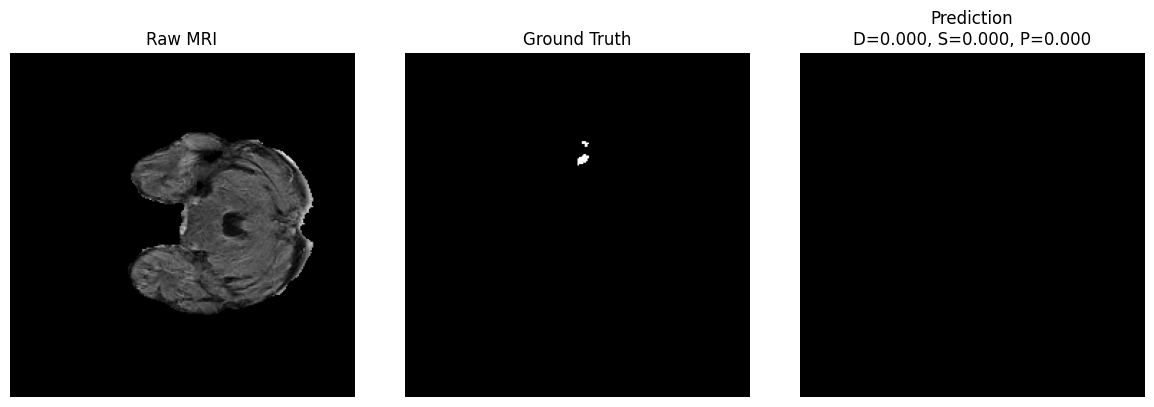

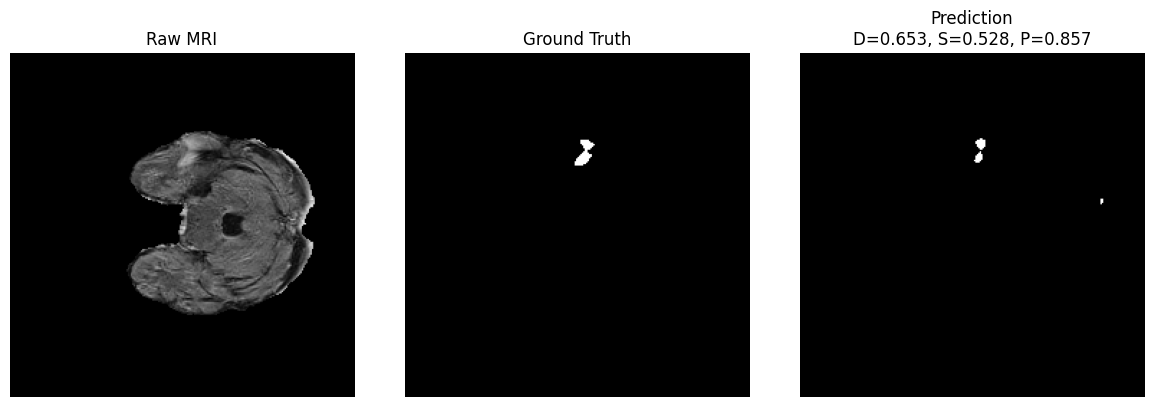

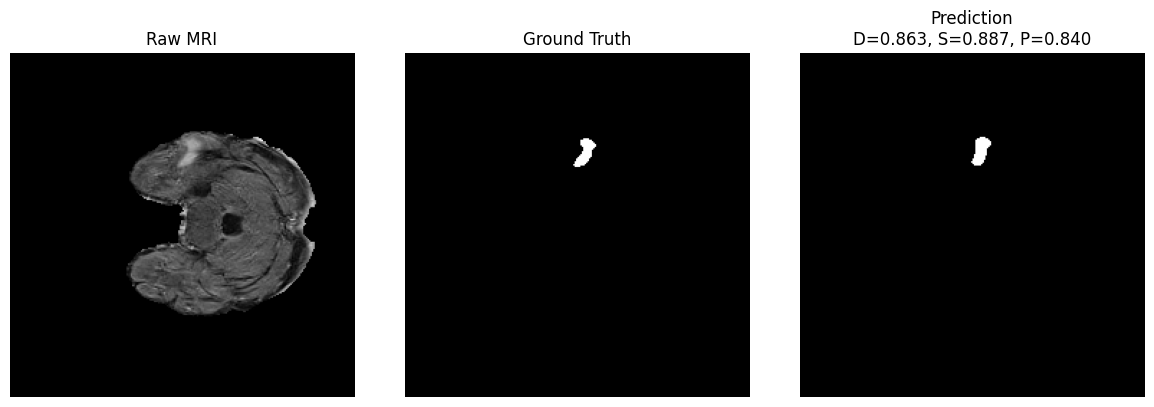

In [ ]:
# Showing channel 0, ground truth, and predicted mask for examples containing tumors 
# Added metrics for each figure here for easier intepretation 

for idx, (img_np, mask_np, pred_np, dice, sensitivity, ppv) in enumerate(saved_examples):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(img_np[0], cmap="gray", vmin=img_np[0].min(), vmax=img_np[0].max())
    axes[0].set_title("Raw MRI")
    axes[0].axis("off")

    axes[1].imshow(mask_np, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Ground Truth")
    axes[1].axis("off")

    axes[2].imshow(pred_np, cmap="gray", vmin=0, vmax=1)
    axes[2].set_title(f"Prediction\nD={dice:.3f}, S={sensitivity:.3f}, P={ppv:.3f}")
    axes[2].axis("off")


    plt.tight_layout()
    plt.show()

## Visualize Overlay Comparison

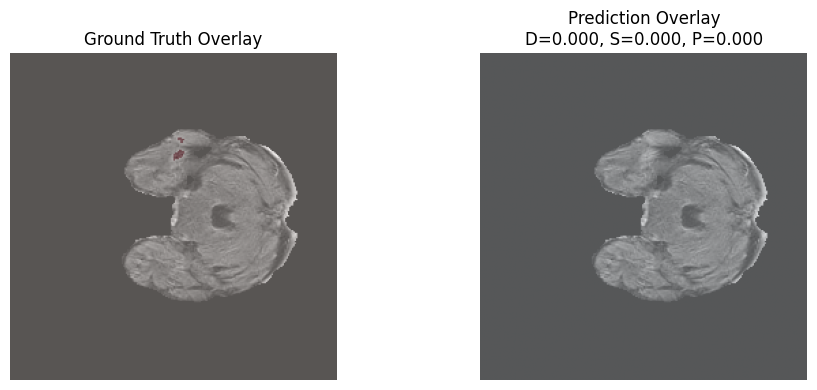

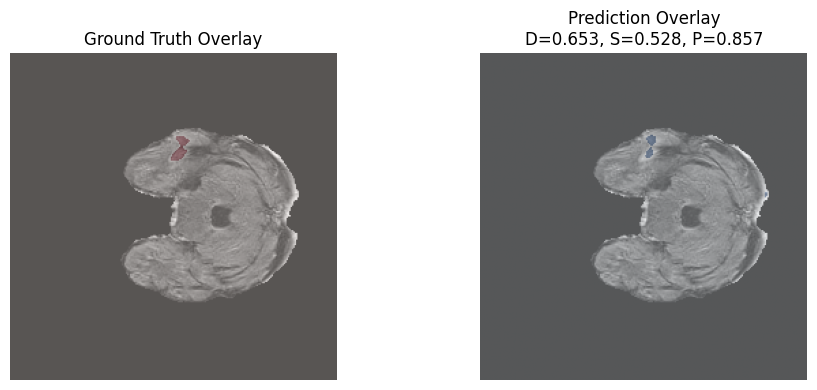

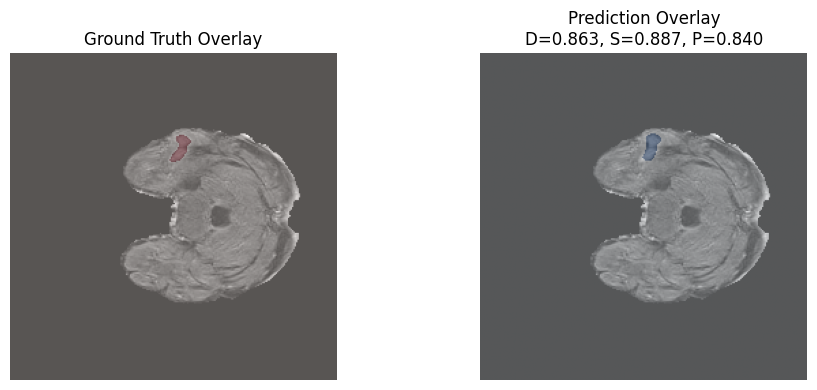

In [168]:
# Overlay the ground truth and predicted masks on channel 0

for idx, (img_np, mask_np, pred_np, dice, sensitivity, ppv) in enumerate(saved_examples):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].imshow(img_np[0], cmap="gray", vmin=img_np[0].min(), vmax=img_np[0].max())
    axes[0].imshow(mask_np, cmap="Reds", alpha=0.35)
    axes[0].set_title("Ground Truth Overlay")
    axes[0].axis("off")

    axes[1].imshow(img_np[0], cmap="gray", vmin=img_np[0].min(), vmax=img_np[0].max())
    axes[1].imshow(pred_np, cmap="Blues", alpha=0.35)
    axes[1].set_title(f"Prediction Overlay\nD={dice:.3f}, S={sensitivity:.3f}, P={ppv:.3f}")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

## Summary of CNN Segmentation Results

In [169]:
print("Summary of U-Net Results")
print(f"Preprocessing used: {preprocess_function.__name__}")
print(f"Number of selected volumes: {len(selected_volumes)}")
print(f"Train / Val / Test volumes: {len(train_vols)} / {len(val_vols)} / {len(test_vols)}")

# Edited to examine exactly how many slices were used in results
# Also includes Mean +- STD here as well rather than just mean 

print(f"Number of test slices in results table: {len(all_dice)}")
print(f"Dice: {np.mean(all_dice):.4f} ± {np.std(all_dice):.4f}")
print(f"Sensitivity: {np.mean(all_sensitivity):.4f} ± {np.std(all_sensitivity):.4f}")
print(f"PPV: {np.mean(all_ppv):.4f} ± {np.std(all_ppv):.4f}")



# print(f"Mean Dice: {np.mean(all_dice):.4f}")
# print(f"Mean Sensitivity: {np.mean(all_sensitivity):.4f}")
# print(f"Mean PPV: {np.mean(all_ppv):.4f}")

Summary of U-Net Results
Preprocessing used: preprocess_baseline
Number of selected volumes: 5
Train / Val / Test volumes: 3 / 1 / 1
Number of test slices in results table: 80
Dice: 0.8330 ± 0.1549
Sensitivity: 0.9356 ± 0.1260
PPV: 0.7696 ± 0.1719
